# Operaciones de aprendizaje automático
## Maestría en Inteligencia Artificial Aplicada

### TC5061 | Proyecto MiBici: propuesta y base reproducible | Colaborativo

#### **Equipo:** 7
#### **Nombre:** Daniel Sánchez Hernández
#### **Matrícula:** A01840324

## Objetivo
Análisis exploratorio de datos (EDA) de los viajes de MiBici orientado a la **P1 (regresión)**: ¿cuántos viajes se iniciarán en una estación o zona en un periodo futuro?

El EDA busca evidencia para definir, con criterio propio, la unidad de predicción (estación o zona), el periodo (hora, día u otro) y las decisiones de limpieza de datos que afectan a esa pregunta.

## Datos de entrada
- **Viajes:** `data/interim/viajes_2020-01_2026-09.parquet`, generado y validado en `0.02-dsh-exploracion-carga.ipynb` (81 meses, 27086557 registros).
- **Estaciones:** la nomenclatura más reciente en `data/raw/estaciones/`.

Antes de ejecutar este notebook se debe ejecutar `0.02-dsh-exploracion-carga.ipynb`, que descarga los datos y genera el Parquet.

In [14]:
# Importación de librerías y registro de versiones (evidencia de reproducibilidad)
from pathlib import Path
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", sns.__version__)

Python      : 3.11.17
pandas      : 3.0.5
numpy       : 1.26.4
matplotlib  : 3.11.2
seaborn     : 0.13.2


## Configuración global

- **Rutas:** Parquet de viajes y carpeta de la nomenclatura de estaciones.
- **Random seed:** para que cualquier muestreo sea reproducible.
- **Opciones de visualización** de pandas.
- **Colores:** paleta Okabe-Ito, apta para daltonismo, referida por nombre.

In [15]:
# Rutas del proyecto (el notebook se ejecuta desde notebooks/)
RUTA_PROYECTO = Path.cwd().parent
RUTA_PARQUET_VIAJES = RUTA_PROYECTO / "data" / "interim" / "viajes_2020-01_2026-09.parquet"
RUTA_ESTACIONES_CRUDAS = RUTA_PROYECTO / "data" / "raw" / "estaciones"

SEMILLA = 42

# Opciones de visualización de pandas
pd.set_option("display.max_columns", None)   # mostrar todas las columnas
pd.set_option("display.max_rows", 120)       # suficiente para tablas mensuales
pd.set_option("display.width", 200)          # ancho suficiente para tablas amplias

# Paleta Okabe-Ito (apta para daltonismo)
AZUL = "#0072B2"
NARANJA = "#E69F00"
AMARILLO = "#F0E442"
VERDE = "#009E73"

## Carga de los datos

El Parquet conserva los tipos definidos en la lectura (enteros que aceptan nulos, fechas y categorías), por lo que no hace falta volver a convertirlos. De la nomenclatura se toma el archivo más reciente.

In [16]:
# Carga de viajes (Parquet) y de la nomenclatura más reciente
viajes = pd.read_parquet(RUTA_PARQUET_VIAJES)
ruta_nomenclatura = sorted(RUTA_ESTACIONES_CRUDAS.glob("nomenclatura_*.csv"))[-1]
estaciones = pd.read_csv(ruta_nomenclatura)

print("Viajes     :", viajes.shape)
print(f"Memoria    : {viajes.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
print("Estaciones :", estaciones.shape, "|", ruta_nomenclatura.name)
print("-" * 45)
print(viajes.dtypes.to_string())
print("-" * 45)
print(estaciones.dtypes.to_string())

Viajes     : (27086557, 9)
Memoria    : 1265.8 MB
Estaciones : (484, 5) | nomenclatura_2026_09.csv
---------------------------------------------
Viaje_Id                      Int64
Usuario_Id                    Int64
Genero                     category
Año_de_nacimiento             Int16
Inicio_del_viaje     datetime64[us]
Fin_del_viaje        datetime64[us]
Origen_Id                     Int32
Destino_Id                    Int32
periodo_archivo            category
---------------------------------------------
id              int64
name              str
latitude      float64
longitude     float64
dpcapacity      int64


## Paso 2: Análisis exploratorio de datos (EDA)

### 2.1 Calidad de los datos

Antes de analizar distribuciones y patrones se revisan los problemas que pueden distorsionar el conteo de viajes, que es la base de la P1:
- **Duplicados:** filas idénticas e identificadores de viaje repetidos.
- **Duración de los viajes:** viajes con duración negativa, cero o extremadamente larga.
- **Estaciones:** estaciones de los viajes que no están en la nomenclatura, y al revés.

En esta sección solo se cuantifican los problemas; las decisiones se toman en la limpieza de datos.

In [17]:
# Duplicados: filas idénticas en todas las columnas e identificadores de viaje repetidos
filas_duplicadas = viajes.duplicated()
ids_repetidos = viajes["Viaje_Id"].duplicated()

print("Filas idénticas a una anterior :", filas_duplicadas.sum())
print("Viaje_Id repetidos             :", ids_repetidos.sum())
print("Viaje_Id repetidos sin ser fila idéntica:", (ids_repetidos & ~filas_duplicadas).sum())
print("-" * 45)

# En qué meses aparecen las filas duplicadas
duplicados_por_mes = viajes.loc[filas_duplicadas, "periodo_archivo"].value_counts()
print(duplicados_por_mes[duplicados_por_mes > 0].sort_index().to_string())

Filas idénticas a una anterior : 758
Viaje_Id repetidos             : 758
Viaje_Id repetidos sin ser fila idéntica: 0
---------------------------------------------
periodo_archivo
2026-09    758


In [18]:
# Duración de cada viaje en minutos
duracion_min = (viajes["Fin_del_viaje"] - viajes["Inicio_del_viaje"]).dt.total_seconds().div(60).astype("float32")

print("Duración negativa      :", (duracion_min < 0).sum())
print("Duración cero          :", (duracion_min == 0).sum())
print("Duración > 24 horas    :", (duracion_min > 24 * 60).sum())
print("-" * 45)

# Percentiles para ver la forma de la distribución sin que los extremos la oculten
percentiles = [0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]
duracion_min.describe(percentiles=percentiles).round(2).to_frame("duracion_min").T

Duración negativa      : 0
Duración cero          : 55035
Duración > 24 horas    : 159
---------------------------------------------


,count,mean,std,min,0.1%,1%,5%,25%,50%,75%,95%,99%,99.9%,max
duracion_min,27086557.0,11.0,15.48,0.0,0.0,0.2,2.02,5.7,9.45,14.75,24.15,32.8,58.72,28150.77


In [19]:
# Estaciones de los viajes contra estaciones de la nomenclatura
ids_nomenclatura = set(estaciones["id"])
ids_origen = set(viajes["Origen_Id"].unique().tolist())
ids_destino = set(viajes["Destino_Id"].unique().tolist())

sin_nomenclatura = sorted((ids_origen | ids_destino) - ids_nomenclatura)
sin_viajes = sorted(ids_nomenclatura - (ids_origen | ids_destino))
viajes_afectados = (viajes["Origen_Id"].isin(sin_nomenclatura) | viajes["Destino_Id"].isin(sin_nomenclatura)).sum()

print("Estaciones en viajes sin nomenclatura:", len(sin_nomenclatura), sin_nomenclatura)
print("Viajes que usan esas estaciones      :", viajes_afectados)
print("Estaciones en nomenclatura sin viajes:", len(sin_viajes))

Estaciones en viajes sin nomenclatura: 3 [124, 405, 407]
Viajes que usan esas estaciones      : 3961
Estaciones en nomenclatura sin viajes: 12


**Observaciones de la calidad de los datos:**
- **Duplicados:** 758 filas son idénticas a otra en todas sus columnas, y son exactamente los 758 `Viaje_Id` repetidos; ningún identificador se repite con contenido distinto. Son copias exactas y todas están en el archivo de 2026-09, lo que apunta a un error de publicación de ese mes. Eliminarlas no pierde información.
- **Duración:** no hay duraciones negativas. Hay 55035 viajes de duración cero (0.20%) y el 1% dura 12 segundos o menos (0.20 min), lo que sugiere intentos de retiro que no se concretaron. Para la P1 importan porque inflarían el conteo de viajes iniciados.
- **Viajes muy largos:** 159 viajes duran más de 24 horas, con un máximo de 28150.77 min (unos 19.5 días). La mediana es de 9.45 min y el 99.9% dura 58.72 min o menos. Un viaje largo cuenta una sola vez como inicio, así que afecta el análisis de duración pero no el conteo de la P1.
- **Estaciones:** 3 estaciones de los viajes (124, 405 y 407) no aparecen en la nomenclatura vigente; las usan 3961 viajes (0.01%). Esos viajes se pueden contar por estación, pero no ubicar en el mapa ni asignar a una zona. Además, 12 estaciones de la nomenclatura no tienen viajes en el rango (posiblemente nuevas o inactivas, por verificar).

### 2.2 Estadísticas descriptivas

Los identificadores (`Viaje_Id`, `Usuario_Id`, `Origen_Id`, `Destino_Id`) son números pero no cantidades: su media no tiene significado, por lo que se describen como categóricas. Las variables numéricas con significado son la duración del viaje, calculada en la sección anterior, y el año de nacimiento.

In [20]:
# Variables numéricas: estadísticas descriptivas con skewness y kurtosis
numericas = pd.DataFrame({"duracion_min": duracion_min,
                          "Año_de_nacimiento": viajes["Año_de_nacimiento"].astype("float32"),
})
estadisticas = numericas.describe().T
estadisticas["skewness"] = numericas.skew()
estadisticas["kurtosis"] = numericas.kurt()
estadisticas.astype("float64").round(2)  # float64 para que el redondeo se muestre exacto

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
duracion_min,27086557.0,11.00,15.48,0.0,5.7,9.45,14.75,28150.77,685.3,989894.31
Año_de_nacimiento,27051936.0,1989.06,16.91,1.0,1984.0,1992.00,1997.00,2023.00,-67.3,7619.17


In [21]:
# Variables categóricas: valores distintos, valor más frecuente y su frecuencia
columnas_categoricas = ["Genero", "Origen_Id", "Destino_Id", "periodo_archivo"]
viajes[columnas_categoricas].astype("category").describe().T

,count,unique,top,freq
Genero,26948912,2,M,19638215
Origen_Id,27086557,475,51,567876
Destino_Id,27086557,475,51,716503
periodo_archivo,27086557,81,2026-09,490056


In [22]:
# Género: conteo y porcentaje, incluyendo los nulos
for columna in ["Genero"]:
    conteo = pd.concat([viajes[columna].value_counts(dropna=False),
                        viajes[columna].value_counts(dropna=False, normalize=True).mul(100).round(2)],
                       axis=1, keys=["count", "percent"],
    )
    print(conteo)
    print("-" * 45)

           count  percent
Genero                   
M       19638215    72.50
F        7310697    26.99
NaN       137645     0.51
---------------------------------------------


**Observaciones de las estadísticas descriptivas:**
- **Duración:** media de 11.00 min y mediana de 9.45 min. La skewness (685.30) y la kurtosis (989894.31) son extremas: unos pocos viajes de días estiran la cola derecha. La mediana y los percentiles describen mejor el viaje típico que la media.
- **Año de nacimiento:** el 50% central está entre 1984 y 1997 (mediana 1992), pero el rango va de 1 a 2023. La skewness negativa (-67.30) y la kurtosis alta (7619.17) vienen de valores imposibles en el extremo bajo; también hay años recientes poco plausibles. Se cuantifican en la siguiente sección.
- **Género:** 72.50% `M`, 26.99% `F` y 0.51% nulos.
- **Estaciones:** la estación 51 es la más frecuente como origen (567876 viajes, 2.10% del total) y como destino (716503, 2.65%); recibe más viajes de los que salen de ella.
- **Periodos:** 2026-09 es el mes con más registros (490056), consistente con el inventario.

### 2.3 Distribuciones

Para las gráficas se usa una muestra aleatoria de 500000 viajes con la random seed del proyecto: con 27 millones de puntos la KDE tarda mucho y la forma de la distribución no cambia. Las estadísticas de las secciones anteriores sí usan todos los datos.

En la duración, la gráfica se limita al percentil 99.9 (58.72 min) para que la cola extrema no aplaste el resto de la distribución; el recorte es solo visual.

In [23]:
def graficar_distribucion(serie, titulo, etiqueta):
    """Histograma con KDE y boxplot horizontal con la media de una variable numérica."""
    valores = serie.dropna()
    fig, (ax_hist, ax_box) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                                          gridspec_kw={"height_ratios": [3, 1]})
    sns.histplot(valores, stat="density", bins=50, color=AZUL, ax=ax_hist)
    sns.kdeplot(valores, color=AMARILLO, linestyle="--", linewidth=2, ax=ax_hist)
    sns.boxplot(x=valores, orient="h", color=AZUL, showmeans=True, ax=ax_box,
                meanprops={"marker": "s", "markerfacecolor": AMARILLO, "markeredgecolor": AMARILLO, "markersize": 6})
    ax_hist.set_title(titulo)
    ax_box.set_xlabel(etiqueta)
    plt.tight_layout()
    plt.show()

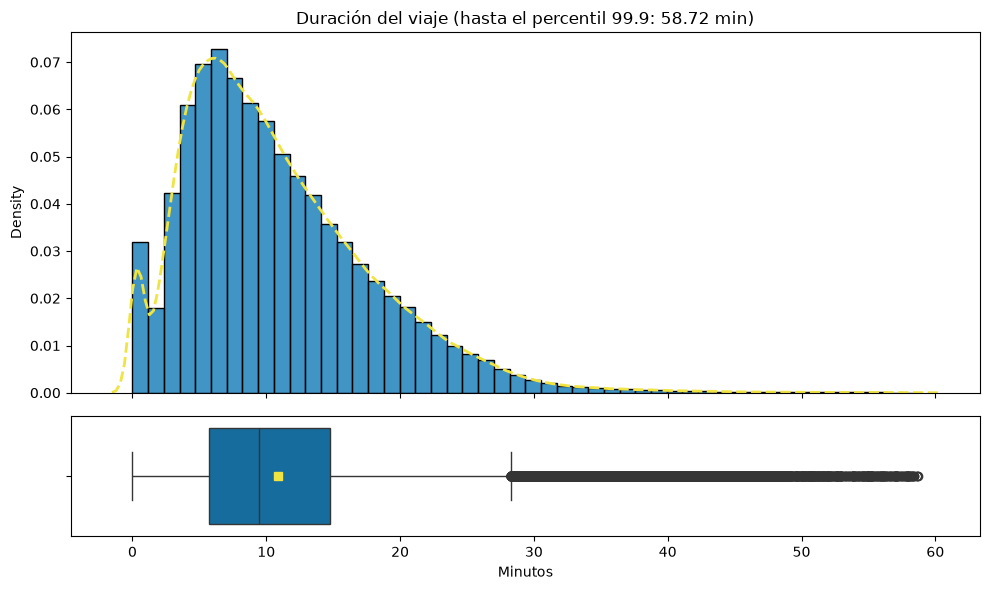

In [24]:
# Muestra reproducible para las gráficas
muestra = numericas.sample(n=500_000, random_state=SEMILLA)

limite_duracion = duracion_min.quantile(0.999)
graficar_distribucion(muestra.loc[muestra["duracion_min"] <= limite_duracion, "duracion_min"],
                      f"Duración del viaje (hasta el percentil 99.9: {limite_duracion:.2f} min)", "Minutos")

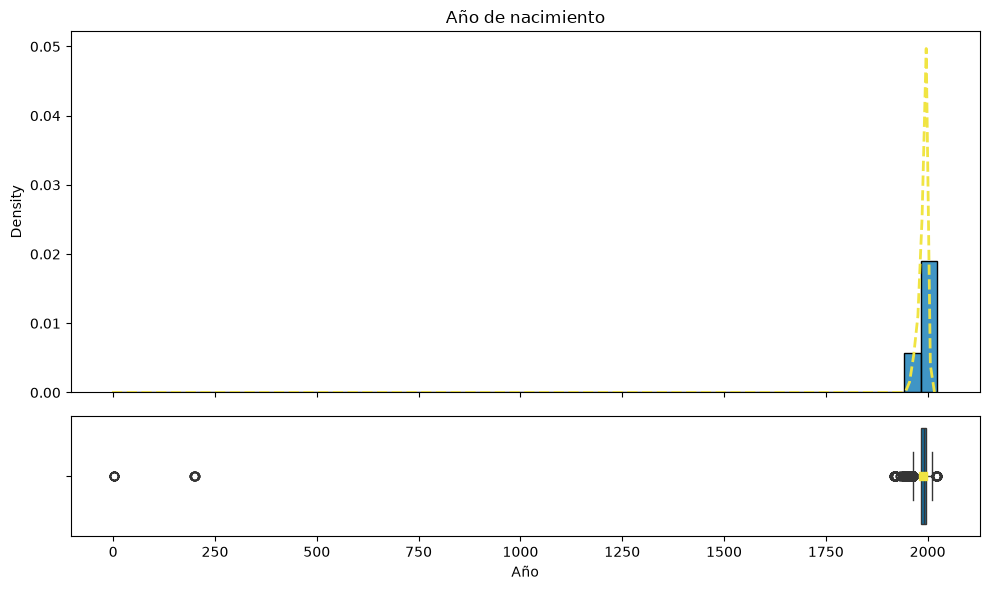

In [25]:
graficar_distribucion(muestra["Año_de_nacimiento"], "Año de nacimiento", "Año")

In [26]:
# Valores extremos del año de nacimiento: los 10 más bajos y los 10 más altos, con su número de viajes
conteo_anios = viajes["Año_de_nacimiento"].value_counts().sort_index()
print("Años más bajos:")
print(conteo_anios.head(10).to_string())
print("-" * 45)
print("Años más altos:")
print(conteo_anios.tail(10).to_string())

Años más bajos:
Año_de_nacimiento
1        747
199      316
200      189
1420       3
1917      43
1918     589
1920    2742
1922     340
1931      26
1933      68
---------------------------------------------
Años más altos:
Año_de_nacimiento
2004    324366
2005    199539
2006    132968
2007     66494
2008     27803
2009      5014
2010       918
2021       571
2022       379
2023      1151


**Observaciones de las distribuciones:**
- **Duración, dos poblaciones:** la mayoría de los viajes forma una curva con moda cerca de 6 a 7 min. Aparte, hay un pico pegado al cero, separado del resto por un valle, consistente con los viajes de duración cero o de segundos de la revisión de calidad (posibles retiros que no se concretaron). Conviene tratarlos como un grupo distinto en la limpieza de datos.
- **Duración, cola derecha:** el boxplot marca como outliers los viajes de más de unos 28 min (1.5 veces el rango intercuartílico sobre el tercer cuartil), pero los viajes de 30 a 60 min son plausibles. Los valores problemáticos son los de horas o días, que quedan fuera de la gráfica por el recorte en el percentil 99.9. La media (cuadro amarillo) queda a la derecha de la mediana por la asimetría.
- **Año de nacimiento, valores imposibles:** 1 (747 viajes), 199 (316), 200 (189) y 1420 (3). Los valores 199 y 200 podrían ser años capturados de forma incompleta (por ejemplo, 199X o 200X), pero no hay forma de recuperarlos.
- **Año de nacimiento, valores poco plausibles:** 1917 a 1922 (3714 viajes, con 2742 solo en 1920), que implicarían usuarios de más de 100 años, y 2021 a 2023 (2101 viajes), que implicarían usuarios de 0 a 5 años. Entre 2010 y 2021 no hay ningún año, lo que separa estos valores de los usuarios jóvenes reales. La concentración en 1920 sugiere un valor capturado por defecto (interpretación).
- **Impacto en la P1:** son viajes reales con un dato de usuario incorrecto. Si se eliminaran, se perderían inicios de viaje del conteo; si el año llegara a usarse, lo adecuado sería tratarlo como nulo y conservar el viaje.